# Homework 5: Demosaicing
## Name: Jon Knapp
### Date: November 17, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

I used Claude (Anthropic) to write and debug the demosaicing and evaluation code and to draft the written answers, which I then reviewed and edited. I verified its work the way item 10 asks: both implementations are compared against the lecture 7 reference implementations in `make_figures.py` and against a second, independent published implementation (`colour-demosaicing`), with the border and the interior separated; the measured sites are tested to come back bit-for-bit; and every number in the written answers was checked against the notebook's printed output.

**Which file.** `IMG_0732.DNG`, a Bayer DNG from my Homework 2 checkerboard calibration series (iPhone 16 Pro Max main camera, Halide, ISO 64, 1/194 s). It has hard black-to-white edges in every direction and a block of small printed text under the board, which is the finest high-contrast detail I have in one frame. Every item below uses this one file so the numbers compare.

**Project 2.** The functions in this notebook (`read_cfa`, `align_rggb`, `quarter_res_reference`, `mosaic_rggb`, `demosaic_bilinear`, `demosaic_mhc`, `psnr`) are written to be lifted unchanged into the Project 2 package as the demosaicing stage of Part A, and the checks in items 3, 10 and 12 are written so they can become pytest tests there. Project 2 builds the same reference from the averaged burst instead of one frame; items 15 and 16 show why.

In [1]:
# If rawpy or tifffile isn't installed:  %pip install rawpy tifffile
import ast
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import tifffile
from scipy.ndimage import correlate

# This notebook lives in EE513/Project 2; the captures are in EE513/Project 1.
EE513 = Path.cwd().resolve().parent
P1_DIR = EE513 / "Project 1"
RAW_PATH = P1_DIR / "Homework 2 Image Captures" / "Checkerboard" / "IMG_0732.DNG"

# Saturation measured in Project 1 (Color and Accuracy, item 1): the green sites pile up from
# about 3950 DN, so 3940 DN is the usable ceiling, not the 4095 DN WhiteLevel tag.
SAT_DN = 3940.0
MARGIN = 4            # border excluded on every side for the "middle of the frame" scores (item 13)

if not RAW_PATH.exists():
    raise FileNotFoundError(f"Raw file not found: {RAW_PATH}")
print(f"Raw file: {RAW_PATH.relative_to(EE513)}")

Raw file: Project 1\Homework 2 Image Captures\Checkerboard\IMG_0732.DNG


## Part 1: A reference you can trust

### Problem 1: Read the CFA pattern from your file rather than assuming it is RGGB. If yours isn't RGGB, offset the mosaic by one row, one column, or both so that the top left site is red.
_Deliverable: One line giving your CFA pattern and the offset you used._

In [2]:
def read_cfa(path):
    """Raw mosaic (DN, float64), CFA pattern as a 4-letter string read top-left, top-right,
    bottom-left, bottom-right, the black level of each site of the 2 x 2 tile, and the
    WhiteLevel tag. The pattern comes from the file (rawpy's raw_pattern), never assumed."""
    with rawpy.imread(str(path)) as r:
        mosaic = r.raw_image_visible.astype(np.float64)          # copy before the file closes
        pattern = r.raw_pattern.copy()
        desc = r.color_desc.decode()
        black = np.asarray(r.black_level_per_channel, dtype=np.float64)
        white = float(r.white_level)
    cfa = "".join(desc[pattern[i, j]] for i in range(2) for j in range(2))
    black_tile = np.array([[black[pattern[i, j]] for j in range(2)] for i in range(2)])
    return mosaic, cfa, black_tile, white


def cfa_from_tags(path):
    """The same pattern straight from the DNG's CFAPattern tag (raw sub-IFD), as a cross-check."""
    names = {0: "R", 1: "G", 2: "B"}
    with tifffile.TiffFile(path) as t:
        for page in t.pages:
            for p in [page, *(page.pages or [])]:
                if "CFAPattern" in p.tags:
                    return "".join(names[v] for v in p.tags["CFAPattern"].value)
    return None


# Offset (rows, columns) that puts a red site at the top left
OFFSETS = {"RGGB": (0, 0), "GRBG": (0, 1), "GBRG": (1, 0), "BGGR": (1, 1)}


def align_rggb(x, cfa):
    """Shift a mosaic so its top-left site is red, then trim to even height and width."""
    dy, dx = OFFSETS[cfa]
    x = x[dy:, dx:]
    h, w = (s // 2 * 2 for s in x.shape[:2])
    return x[:h, :w]


mosaic_dn, CFA, BLACK_TILE, WHITE_TAG = read_cfa(RAW_PATH)
tag_cfa = cfa_from_tags(RAW_PATH)
assert tag_cfa in (None, CFA), f"rawpy says {CFA}, the CFAPattern tag says {tag_cfa}"

# Check the shift: the pattern seen from the new origin must read RGGB.
dy, dx = OFFSETS[CFA]
shifted = "".join(CFA[((i + dy) % 2) * 2 + (j + dx) % 2] for i in range(2) for j in range(2))
assert shifted == "RGGB", shifted

print(f"CFA pattern: {CFA} (rawpy raw_pattern; CFAPattern tag: {tag_cfa}); "
      f"offset {dy} row(s), {dx} column(s) so the top-left site is red")
print(f"Mosaic {mosaic_dn.shape[1]} x {mosaic_dn.shape[0]}; black level per site {BLACK_TILE.tolist()} DN; "
      f"WhiteLevel tag {WHITE_TAG:.0f} DN; saturation used {SAT_DN:.0f} DN; "
      f"largest raw value in this file {mosaic_dn.max():.0f} DN")

CFA pattern: BGGR (rawpy raw_pattern; CFAPattern tag: BGGR); offset 1 row(s), 1 column(s) so the top-left site is red
Mosaic 4032 x 3024; black level per site [[528.0, 528.0], [528.0, 528.0]] DN; WhiteLevel tag 4095 DN; saturation used 3940 DN; largest raw value in this file 1796 DN


**CFA pattern: BGGR**, read from the file (rawpy's `raw_pattern` and the DNG `CFAPattern` tag agree). I offset the mosaic by **one row and one column** (dropping the first row and column, then trimming to even size), which puts a red site at the top left.

### Problem 2: Build a ground truth image from the mosaic. Subtract the black level, divide by the span from black up to saturation, and then take each 2 by 2 block to one pixel of a quarter resolution image, using the red site, the mean of the two green sites, and the blue site.
_Deliverable: The reference image, displayed._

In [3]:
def normalize(mosaic, black_tile, sat):
    """Black level subtracted per Bayer site, divided by the span from black to saturation.
    Done in the file's own coordinates, before any shift, so each site gets its own black."""
    h, w = mosaic.shape
    black = np.tile(black_tile, (h // 2 + 1, w // 2 + 1))[:h, :w]
    return (mosaic - black) / (sat - black)


def quarter_res_reference(m):
    """RGGB mosaic -> quarter-resolution RGB: red site, mean of the two greens, blue site.
    Nothing is interpolated: every value is a measurement (or the mean of two)."""
    return np.dstack([m[0::2, 0::2], 0.5 * (m[0::2, 1::2] + m[1::2, 0::2]), m[1::2, 1::2]])


lin_mosaic = align_rggb(normalize(mosaic_dn, BLACK_TILE, SAT_DN), CFA)      # RGGB, [0, 1] of the raw range
ref = quarter_res_reference(lin_mosaic)
ref = ref[: ref.shape[0] // 2 * 2, : ref.shape[1] // 2 * 2]              # even size so it can be re-mosaicked

print(f"Aligned mosaic {lin_mosaic.shape[1]} x {lin_mosaic.shape[0]} -> reference "
      f"{ref.shape[1]} x {ref.shape[0]} x 3 (linear camera RGB, 1.0 = saturation)")
print("Reference range per channel (R, G, B): "
      + ", ".join(f"{ref[..., c].min():.4f} to {ref[..., c].max():.4f}" for c in range(3)))

Aligned mosaic 4030 x 3022 -> reference 2014 x 1510 x 3 (linear camera RGB, 1.0 = saturation)
Reference range per channel (R, G, B): 0.0018 to 0.2268, 0.0048 to 0.3620, -0.0003 to 0.1181


Display gains (R, G, B): [1.63, 1.0, 3.209], white at 0.325


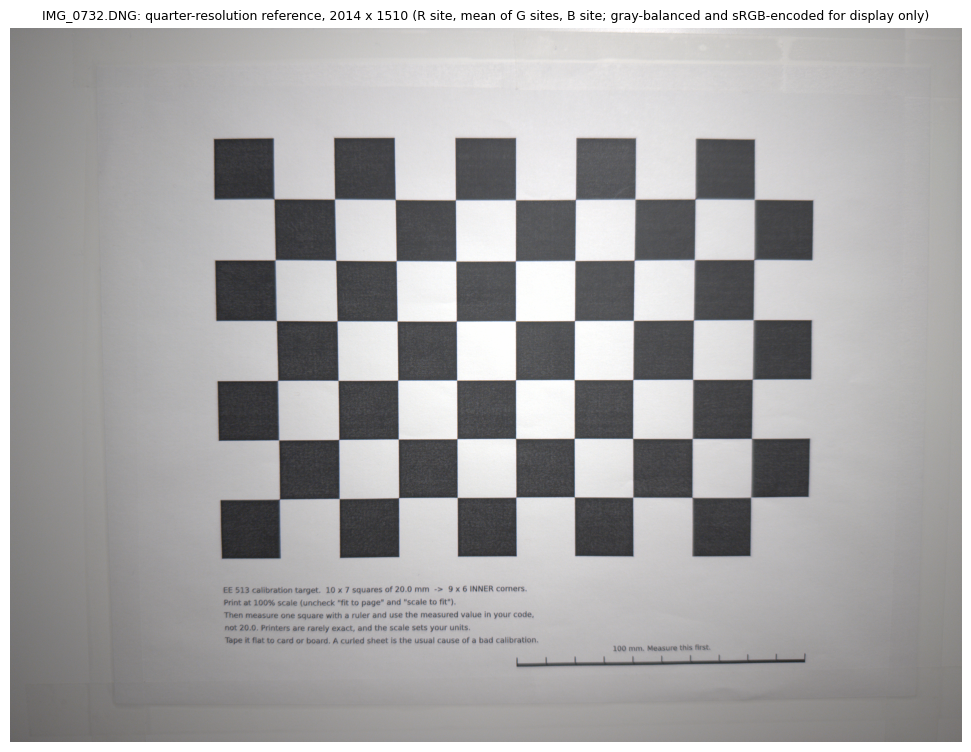

In [4]:
def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


# Display only: neutralize the camera's raw color with gains that make the brightest 1% of the
# reference (the white paper) gray, scale it to 1, and sRGB-encode. Every number in this notebook
# is computed on the unscaled linear camera RGB, never on these display values.
_bright = ref.sum(axis=2) > np.percentile(ref.sum(axis=2), 99)
DISP_GAINS = ref[_bright].mean(axis=0)[1] / ref[_bright].mean(axis=0)
DISP_WHITE = np.percentile(ref * DISP_GAINS, 99.5)


def disp(x):
    return srgb_encode(x * DISP_GAINS / DISP_WHITE)


print(f"Display gains (R, G, B): {np.round(DISP_GAINS, 3).tolist()}, white at {DISP_WHITE:.3f}")
fig, ax = plt.subplots(figsize=(10, 7.6))
ax.imshow(disp(ref))
ax.set_title(f"{RAW_PATH.name}: quarter-resolution reference, {ref.shape[1]} x {ref.shape[0]} "
             "(R site, mean of G sites, B site; gray-balanced and sRGB-encoded for display only)", fontsize=9)
ax.axis("off")
fig.tight_layout()
fig.savefig("hw5_item2_reference.png", dpi=150, bbox_inches="tight")
plt.show()

### Problem 3: Mosaic the reference back down, so that you have a Bayer image whose correct answer you know exactly. Then confirm the round trip: re-reading the mosaic's sampled sites has to return the reference values unchanged.
_Deliverable: The round-trip assertion, passing._

In [5]:
def bayer_masks(shape):
    """Boolean masks of an RGGB mosaic: red, green in a red row, green in a blue row, blue."""
    r = np.zeros(shape, bool); r[0::2, 0::2] = True
    gr = np.zeros(shape, bool); gr[0::2, 1::2] = True
    gb = np.zeros(shape, bool); gb[1::2, 0::2] = True
    b = np.zeros(shape, bool); b[1::2, 1::2] = True
    return r, gr, gb, b


def mosaic_rggb(rgb):
    """Keep one color per pixel in an RGGB pattern."""
    out = np.empty(rgb.shape[:2])
    out[0::2, 0::2] = rgb[0::2, 0::2, 0]
    out[0::2, 1::2] = rgb[0::2, 1::2, 1]
    out[1::2, 0::2] = rgb[1::2, 0::2, 1]
    out[1::2, 1::2] = rgb[1::2, 1::2, 2]
    return out


def sampled_sites_match(mosaic, rgb):
    """True if every sampled site of `mosaic` equals the same channel of `rgb` at that pixel, bit for bit."""
    r, gr, gb, b = bayer_masks(mosaic.shape)
    return all(np.array_equal(mosaic[mask], rgb[..., c][mask])
               for mask, c in ((r, 0), (gr, 1), (gb, 1), (b, 2)))


test_mosaic = mosaic_rggb(ref)
assert sampled_sites_match(test_mosaic, ref), "round trip failed"
assert np.array_equal(test_mosaic[0::2, 0::2], ref[0::2, 0::2, 0])   # and once more, written out by hand
assert np.array_equal(test_mosaic[1::2, 1::2], ref[1::2, 1::2, 2])
print(f"Round trip passed: all {test_mosaic.size:,} sampled sites return the reference values exactly "
      f"(np.array_equal, no tolerance).")

Round trip passed: all 3,041,140 sampled sites return the reference values exactly (np.array_equal, no tolerance).


### Problem 4: Explain why you couldn't have used a demosaiced version of the same capture as your reference instead.
_Deliverable: Two or three sentences._

A demosaiced image is two-thirds interpolation: at every pixel, two of the three channels were invented by some algorithm, so it isn't a measurement of the scene. Scoring a demosaicer against it measures how closely the method imitates whichever demosaicer made the reference, and a method that matches that algorithm, including its errors, would get the best score. The quarter-resolution image has three measured values at every pixel, so its errors are the sensor's noise and not any algorithm's guesses.

### Problem 5: Say what the quarter resolution construction costs you.
_Deliverable: One or two sentences._

It costs three-quarters of the pixels: the reference is half the width and half the height of the sensor, so the test image is a different, coarser image than the one the phone actually demosaics. Detail is relatively finer at that scale, so absolute scores don't carry over to full resolution. It also places the red, green and blue values of one pixel at points up to a pixel apart on the sensor, and it keeps the single frame's noise in every value (item 15).

## Part 2: Two algorithms

### Problem 6: Implement bilinear demosaicing yourself. Interpolate each channel from its own measured neighbors, and take care at the frame border, where a pixel has fewer neighbors than it does in the middle.
_Deliverable: Your code._

In [6]:
# Bilinear kernels, applied to each channel's measured sites only (the others are zero).
K_G = np.array([[0, 1, 0],
                [1, 4, 1],
                [0, 1, 0]]) / 4
K_RB = np.array([[1, 2, 1],
                 [2, 4, 2],
                 [1, 2, 1]]) / 4


def demosaic_bilinear(m):
    """Bilinear demosaicing of an RGGB mosaic.

    Each channel is the correlation of its own measured sites with its kernel, divided by the
    same correlation of the site mask (normalized convolution). In the middle of the frame the
    divisor is exactly 1, so this is ordinary bilinear interpolation. At the border, a missing
    neighbor contributes nothing to either sum, so the pixel is the average of the neighbors it
    actually has; for example a green value at a blue corner site is the mean of 2 greens, not 4.
    At a measured site the divisor is 1 and the only term is the site itself, so it comes back
    unchanged (item 12).
    """
    r, gr, gb, b = bayer_masks(m.shape)
    out = np.empty(m.shape + (3,))
    for c, (mask, k) in enumerate(((r, K_RB), (gr | gb, K_G), (b, K_RB))):
        num = correlate(np.where(mask, m, 0.0), k, mode="constant", cval=0.0)
        den = correlate(mask.astype(float), k, mode="constant", cval=0.0)
        out[..., c] = num / den
    return out


bil = demosaic_bilinear(test_mosaic)
print(f"Bilinear output: {bil.shape}")

Bilinear output: (1510, 2014, 3)


### Problem 7: Implement Malvar, He and Cutler yourself. Start from bilinear and add the correction term for each of the eight cases in the lecture 7 table. Write it as fixed linear filters, with no branching and no per-pixel decisions.
_Deliverable: Your code._

In [7]:
# Correction terms (Malvar, He and Cutler, 2004). Each is a gain times a discrete Laplacian of the
# channel measured at that site, so each sums to zero: it changes detail, never the local mean.
# All taps of a correction filter land on sites of one color: the center pixel's own color.
ALPHA, BETA, GAMMA = 1 / 2, 5 / 8, 3 / 4

LAP_PLUS = np.array([[0, 0, -1, 0, 0],          # center minus the mean of the four same-color
                     [0, 0, 0, 0, 0],           # sites two pixels away (used at R and B sites)
                     [-1, 0, 4, 0, -1],
                     [0, 0, 0, 0, 0],
                     [0, 0, -1, 0, 0]]) / 4
LAP_G = np.array([[0, 0, 1 / 2, 0, 0],          # green Laplacian at a green site: center minus the
                  [0, -1, 0, -1, 0],            # four diagonal greens and the two horizontal greens,
                  [-1, 0, 5, 0, -1],            # with the two vertical greens at half weight
                  [0, -1, 0, -1, 0],            # (the MHC paper's choice; the weights sum to zero)
                  [0, 0, 1 / 2, 0, 0]]) / 5

CORRECTIONS = {
    "G at R or B": ALPHA * LAP_PLUS,             # cases 1, 2: green at a red or a blue site
    "row":         BETA * LAP_G,                 # cases 3, 6: R at a green site in a red row, B at a green in a blue row
    "column":      BETA * LAP_G.T,               # cases 4, 5: R at a green site in a blue row, B at a green in a red row
    "R at B / B at R": GAMMA * LAP_PLUS,         # cases 7, 8: red at a blue site, blue at a red site
}
for name, k in CORRECTIONS.items():
    assert abs(k.sum()) < 1e-15, name


def demosaic_mhc(m):
    """Malvar-He-Cutler demosaicing of an RGGB mosaic: bilinear plus a gradient correction.

    Every correction filter is applied to the whole mosaic; fixed periodic site masks (which
    depend only on position, never on the data) choose which correction each output pixel
    receives. No branches, no thresholds, no per-pixel decisions: the whole method is one linear
    operator, which is why it costs nothing extra to run.

    Border: the corrections reach two pixels out. They are computed with mirror padding
    (scipy 'mirror': d c b | a b c d), which reflects about the edge pixel and so keeps every
    reflected sample on a site of the same color. The bilinear part keeps its own border rule.
    """
    r, gr, gb, b = bayer_masks(m.shape)
    out = demosaic_bilinear(m)
    c = {name: correlate(m, k, mode="mirror") for name, k in CORRECTIONS.items()}
    out[..., 0] += gr * c["row"] + gb * c["column"] + b * c["R at B / B at R"]
    out[..., 1] += (r | b) * c["G at R or B"]
    out[..., 2] += gb * c["row"] + gr * c["column"] + r * c["R at B / B at R"]
    return out


mhc = demosaic_mhc(test_mosaic)
print(f"MHC output: {mhc.shape}")

MHC output: (1510, 2014, 3)


### Problem 8: The eight cases need only four filter patterns between them, because two of them are each other rotated by ninety degrees. Print the four you used.
_Deliverable: Four arrays._

In [8]:
def embed(k, n=5):
    """Center a small kernel in an n x n array."""
    out = np.zeros((n, n))
    o = (n - k.shape[0]) // 2
    out[o:o + k.shape[0], o:o + k.shape[1]] = k
    return out


# The bilinear part of each case, written on the raw mosaic (weights on the target color's sites)
BIL_PART = {
    "G at R or B": embed(np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]]) / 4),
    "row":         embed(np.array([[0, 0, 0], [1, 0, 1], [0, 0, 0]]) / 2),
    "column":      embed(np.array([[0, 1, 0], [0, 0, 0], [0, 1, 0]]) / 2),
    "R at B / B at R": embed(np.array([[1, 0, 1], [0, 0, 0], [1, 0, 1]]) / 4),
}
MHC_FILTERS = {name: BIL_PART[name] + CORRECTIONS[name] for name in CORRECTIONS}

with np.printoptions(precision=4, suppress=True, floatmode="maxprec"):
    for name in ("G at R or B", "row", "R at B / B at R"):
        print(f"{name}   (x 8, matching the paper's table):")
        print(8 * MHC_FILTERS[name], "\n")
    print("column = row rotated by 90 degrees (x 8):")
    print(8 * MHC_FILTERS["column"])
assert np.array_equal(MHC_FILTERS["column"], np.rot90(MHC_FILTERS["row"]))
print("\nEach full filter sums to 1:", {k: round(float(v.sum()), 12) for k, v in MHC_FILTERS.items()})

# The four full filters, applied directly, must give the same interior as bilinear + correction.
r_, gr_, gb_, b_ = bayer_masks(test_mosaic.shape)
direct_R = np.where(r_, test_mosaic, 0) + gr_ * correlate(test_mosaic, MHC_FILTERS["row"]) \
    + gb_ * correlate(test_mosaic, MHC_FILTERS["column"]) + b_ * correlate(test_mosaic, MHC_FILTERS["R at B / B at R"])
inner = (slice(2, -2), slice(2, -2))
print(f"Largest interior difference, four direct filters vs. bilinear + correction (red): "
      f"{np.abs(direct_R[inner] - mhc[..., 0][inner]).max():.2e}")

G at R or B   (x 8, matching the paper's table):
[[ 0.  0. -1.  0.  0.]
 [ 0.  0.  2.  0.  0.]
 [-1.  2.  4.  2. -1.]
 [ 0.  0.  2.  0.  0.]
 [ 0.  0. -1.  0.  0.]] 

row   (x 8, matching the paper's table):
[[ 0.   0.   0.5  0.   0. ]
 [ 0.  -1.   0.  -1.   0. ]
 [-1.   4.   5.   4.  -1. ]
 [ 0.  -1.   0.  -1.   0. ]
 [ 0.   0.   0.5  0.   0. ]] 

R at B / B at R   (x 8, matching the paper's table):
[[ 0.   0.  -1.5  0.   0. ]
 [ 0.   2.   0.   2.   0. ]
 [-1.5  0.   6.   0.  -1.5]
 [ 0.   2.   0.   2.   0. ]
 [ 0.   0.  -1.5  0.   0. ]] 

column = row rotated by 90 degrees (x 8):
[[ 0.   0.  -1.   0.   0. ]
 [ 0.  -1.   4.  -1.   0. ]
 [ 0.5  0.   5.   0.   0.5]
 [ 0.  -1.   4.  -1.   0. ]
 [ 0.   0.  -1.   0.   0. ]]

Each full filter sums to 1: {'G at R or B': 1.0, 'row': 1.0, 'column': 1.0, 'R at B / B at R': 1.0}
Largest interior difference, four direct filters vs. bilinear + correction (red): 1.11e-16


### Problem 9: Show what the two algorithms produced, next to the reference.
_Deliverable: One figure with three panels._

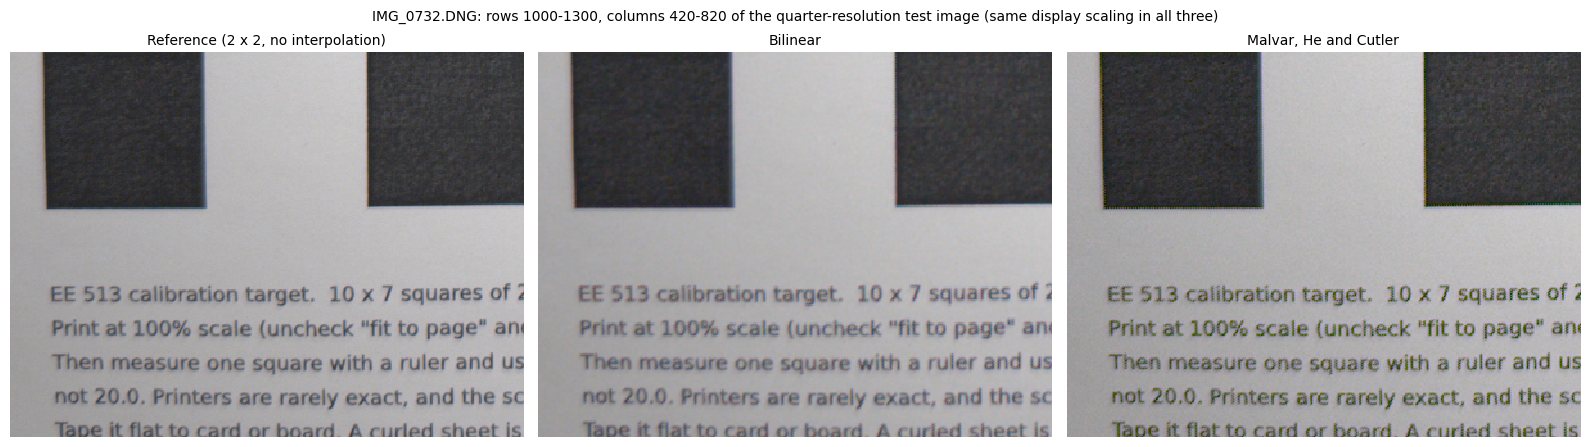

In [9]:
# A region with a checkerboard corner and the smallest printed text (quarter-resolution pixels).
CROP9 = (slice(1000, 1300), slice(420, 820))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, img, title in zip(axes, (ref, bil, mhc),
                          ("Reference (2 x 2, no interpolation)", "Bilinear", "Malvar, He and Cutler")):
    ax.imshow(disp(img[CROP9]), interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle(f"{RAW_PATH.name}: rows {CROP9[0].start}-{CROP9[0].stop}, columns {CROP9[1].start}-{CROP9[1].stop} "
             "of the quarter-resolution test image (same display scaling in all three)", fontsize=10)
fig.tight_layout()
fig.savefig("hw5_item9_three_panels.png", dpi=150, bbox_inches="tight")
plt.show()

### Problem 10: Check both of your implementations against the reference ones in make_figures.py from the lecture 7 slides, which are bilinear_demosaic and mhc_demosaic. They assume an RGGB mosaic, so feed them the aligned version from item 1.
_Deliverable: The largest absolute difference between your output and theirs, for each of the two methods._

In [10]:
# make_figures.py and psu_imaging.py come from the Canvas Slides folder (lecture 7). Put both in
# EE513 (where psu_imaging.py already is) or set SLIDES_DIR to the folder that holds them.
SLIDES_DIR = None

search = ([Path(SLIDES_DIR)] if SLIDES_DIR else []) + [Path.cwd().resolve(), *Path.cwd().resolve().parents]
search += [p / "Slides" for p in list(search)]
MF_PATH = next((p / "make_figures.py" for p in search if (p / "make_figures.py").exists()), None)
PSU_PATH = next((p / "psu_imaging.py" for p in search if (p / "psu_imaging.py").exists()), None)
print(f"make_figures.py: {MF_PATH or 'NOT FOUND'}")
print(f"psu_imaging.py:  {PSU_PATH or 'NOT FOUND'}")


def load_functions(path, names):
    """Load only the named functions from a script (plus its imports, constants and any helper
    functions they call), without running the script's figure-making code."""
    tree = ast.parse(Path(path).read_text(encoding="utf-8"))
    defs = {n.name: n for n in tree.body if isinstance(n, ast.FunctionDef)}
    keep, todo = set(), list(names)
    while todo:                                           # follow calls to other top-level functions
        name = todo.pop()
        if name in keep or name not in defs:
            continue
        keep.add(name)
        todo += [c.func.id for c in ast.walk(defs[name])
                 if isinstance(c, ast.Call) and isinstance(c.func, ast.Name)]
    body = [n for n in tree.body
            if isinstance(n, (ast.Import, ast.ImportFrom))
            or (isinstance(n, ast.Assign) and all(isinstance(t, ast.Name) and t.id.isupper() for t in n.targets))
            or (isinstance(n, ast.FunctionDef) and n.name in keep)]
    # make_figures.py computes HERE = Path(__file__).resolve().parent at the top, and exec()
    # doesn't define __file__, so supply it: the script sees its own location as if run directly.
    ns = {"__name__": "make_figures_subset", "__file__": str(Path(path).resolve())}
    exec(compile(ast.Module(body=body, type_ignores=[]), str(path), "exec"), ns)
    return {n: ns[n] for n in names}


def split_diff(a, b, border=2):
    """Largest |a - b| over the whole frame, within `border` px of the edge, and inside it."""
    d = np.abs(a - b)
    inner = d[border:-border, border:-border]
    edge = d.copy(); edge[border:-border, border:-border] = 0
    return d.max(), edge.max(), inner.max()


THEIRS = {}
if MF_PATH is not None:
    for p in {MF_PATH.parent, *( [PSU_PATH.parent] if PSU_PATH else [] )}:
        sys.path.insert(0, str(p))
    lec = load_functions(MF_PATH, ["bilinear_demosaic", "mhc_demosaic"])
    THEIRS = {"bilinear": lec["bilinear_demosaic"](test_mosaic.copy()),
              "MHC": lec["mhc_demosaic"](test_mosaic.copy())}
    rows = []
    for name, mine in (("bilinear", bil), ("MHC", mhc)):
        theirs = np.asarray(THEIRS[name], dtype=np.float64)
        assert theirs.shape == mine.shape, f"{name}: their output is {theirs.shape}, mine {mine.shape}"
        whole, edge, inner = split_diff(mine, theirs)
        rows.append({"method": name, "max |mine - lecture 7|, whole frame": whole,
                     "border (2 px)": edge, "interior": inner,
                     # the lecture mhc_demosaic ends with np.clip(out, 0, 1); mine doesn't clip
                     "interior, mine clipped to [0, 1]": (split_diff(np.clip(mine, 0, 1), theirs)[2]
                                                          if name == "MHC" else np.nan)})
    cols = [k for k in rows[0] if k != "method"]
    display(pd.DataFrame(rows).style.format("{:.3e}", subset=cols, na_rep="n/a (no clip)").hide(axis="index"))

    # Where the interior MHC difference comes from: values my MHC puts below zero, which the
    # lecture version clips. Count them, and check whether they explain every interior difference.
    inner = (slice(2, -2), slice(2, -2))
    differs = np.abs(mhc - np.asarray(THEIRS["MHC"]))[inner] > 1e-12
    negative = (mhc < 0)[inner]
    print(f"My MHC output: {(mhc < 0).sum():,} values below 0 (lowest {mhc.min():.4f}), none above 1. "
          f"Interior values that differ from lecture 7: {differs.sum():,}, of which {(differs & negative).sum():,} "
          f"are values below 0 in my output.")
    # Item 12's property, checked on the lecture versions too: largest change at a measured site.
    r_, gr_, gb_, b_ = bayer_masks(test_mosaic.shape)
    g_ = gr_ | gb_
    for lec_name, out_ in (("bilinear", np.asarray(THEIRS["bilinear"])), ("MHC", np.asarray(THEIRS["MHC"]))):
        change = max(np.abs(out_[..., 0][r_] - test_mosaic[r_]).max(),
                     np.abs(out_[..., 1][g_] - test_mosaic[g_]).max(),
                     np.abs(out_[..., 2][b_] - test_mosaic[b_]).max())
        print(f"lecture 7 {lec_name}: largest change at a measured site {change:.2e}")
    print(f"(the test mosaic has {(test_mosaic < 0).sum():,} measured value(s) below 0, lowest {test_mosaic.min():.2e})")
else:
    print("! make_figures.py was not found, so item 10 cannot be run yet. Download make_figures.py and "
          "psu_imaging.py from the Canvas Slides folder (lecture 7) and set SLIDES_DIR.")

make_figures.py: C:\Users\jknap\PycharmProjects\EE513\make_figures.py
psu_imaging.py:  C:\Users\jknap\PycharmProjects\EE513\psu_imaging.py


method,"max |mine - lecture 7|, whole frame",border (2 px),interior,"interior, mine clipped to [0, 1]"
bilinear,2.776e-17,2.776e-17,0.000e+00,n/a (no clip)
MHC,1.747e-01,1.747e-01,5.199e-02,1.665e-16


My MHC output: 19,209 values below 0 (lowest -0.0520), none above 1. Interior values that differ from lecture 7: 19,200, of which 19,200 are values below 0 in my output.
lecture 7 bilinear: largest change at a measured site 2.78e-17
lecture 7 MHC: largest change at a measured site 2.93e-04
(the test mosaic has 1 measured value(s) below 0, lowest -2.93e-04)


**A second, independent check.** `make_figures.py` is one reference; `colour-demosaicing` (the Colour developers' published implementation of both methods) is another that nothing here was written against. It runs if the package is installed (`uv pip install colour-demosaicing`) and is skipped otherwise.

In [11]:
try:
    import colour_demosaicing as cdm
except ImportError:
    cdm = None
    print("colour-demosaicing is not installed; skipping this cross-check.")

if cdm is not None:
    ext = {"bilinear": cdm.demosaicing_CFA_Bayer_bilinear(test_mosaic, "RGGB"),
           "MHC": cdm.demosaicing_CFA_Bayer_Malvar2004(test_mosaic, "RGGB")}
    rows = []
    for name, mine in (("bilinear", bil), ("MHC", mhc)):
        whole, edge, inner = split_diff(mine, ext[name])
        rows.append({"method": name, "whole frame": whole, "border (2 px)": edge, "interior": inner})
    print(f"colour-demosaicing {cdm.__version__}: largest |mine - theirs|")
    display(pd.DataFrame(rows).style.format("{:.3e}", subset=["whole frame", "border (2 px)", "interior"])
            .hide(axis="index"))
    print(f"float64 machine epsilon: {np.finfo(np.float64).eps:.2e}")

colour-demosaicing 0.2.7: largest |mine - theirs|


method,whole frame,border (2 px),interior
bilinear,1.032e-01,1.032e-01,0.000e+00
MHC,1.747e-01,1.747e-01,1.665e-16


float64 machine epsilon: 2.22e-16


**Against `make_figures.py`:** bilinear agrees everywhere, with a largest difference of 2.8 &times; 10<sup>-17</sup> (at the border) and 0 in the interior. MHC's largest difference is 0.175 at the border and 0.052 in the interior; with my output clipped to [0, 1], as the lecture version clips its own, the interior difference is 1.7 &times; 10<sup>-16</sup>, under one float64 epsilon. Item 11 explains both.

**Against `colour-demosaicing`:** bilinear 0 in the interior and 0.103 at the border; MHC 1.7 &times; 10<sup>-16</sup> in the interior (under one float64 epsilon, 2.2 &times; 10<sup>-16</sup>) and 0.175 at the border. The interior agreement says the four filters and the eight-case selection are right; all of the disagreement is in the outer two pixels.

### Problem 11: If either difference is larger than floating point rounding, find out why before you go on. A disagreement at the border is a different problem from a disagreement in the middle, and it's worth separating the two.
_Deliverable: One sentence on what caused it, or a statement that there was no disagreement._

In [12]:
def where_they_differ(mine, theirs, tol=1e-12, label=""):
    """Rows and columns (distance from the nearest edge) at which two outputs differ."""
    d = np.abs(mine - theirs).max(axis=2)
    ys, xs = np.nonzero(d > tol)
    if ys.size == 0:
        print(f"{label}: no pixel differs by more than {tol:g}")
        return
    h, w = d.shape
    dist = np.minimum.reduce([ys, xs, h - 1 - ys, w - 1 - xs])
    print(f"{label}: {ys.size:,} pixels differ by more than {tol:g}; distance from the nearest edge "
          f"{dist.min()} to {dist.max()} px; "
          f"{(dist < 2).mean():.1%} of them in the outer 2 px")


for name, mine in (("bilinear", bil), ("MHC", mhc)):
    if THEIRS:
        where_they_differ(mine, np.asarray(THEIRS[name], float), label=f"lecture 7 {name}")
    if cdm is not None:
        where_they_differ(mine, ext[name], label=f"colour-demosaicing {name}")

# The cause, shown directly: colour-demosaicing pads with scipy's default 'reflect' (d c b a | a b c d),
# which repeats the edge pixel, so the first reflected sample lands on a site of the other color.
if cdm is not None:
    edge_sample = test_mosaic[0, :4]
    print("\nTop row starts R G R G:", np.round(edge_sample, 4).tolist())
    print("'reflect' padding puts", np.round(np.pad(edge_sample, (2, 0), mode="symmetric")[:2], 4).tolist(),
          "to its left (G R: colors swapped); 'mirror' puts",
          np.round(np.pad(edge_sample, (2, 0), mode="reflect")[:2], 4).tolist(), "(R G: colors preserved)")

lecture 7 bilinear: no pixel differs by more than 1e-12
colour-demosaicing bilinear: 7,044 pixels differ by more than 1e-12; distance from the nearest edge 0 to 0 px; 100.0% of them in the outer 2 px
lecture 7 MHC: 32,380 pixels differ by more than 1e-12; distance from the nearest edge 0 to 754 px; 43.5% of them in the outer 2 px
colour-demosaicing MHC: 14,080 pixels differ by more than 1e-12; distance from the nearest edge 0 to 1 px; 100.0% of them in the outer 2 px

Top row starts R G R G: [0.0384, 0.0693, 0.0416, 0.0689]
'reflect' padding puts [0.0693, 0.0384] to its left (G R: colors swapped); 'mirror' puts [0.0416, 0.0693] (R G: colors preserved)


**Against `make_figures.py`:** bilinear has no disagreement. MHC has two, with two causes. In the interior, every differing value is one my MHC put below zero (down to &minus;0.052, where the correction overshoots on the dark side of a checkerboard edge), and the lecture `mhc_demosaic` ends with `np.clip(out, 0, 1)`; clipped the same way, mine agrees to 1.7 &times; 10<sup>-16</sup>. At the border, the lecture code filters with OpenCV's `BORDER_REFLECT`, which, like scipy's `reflect`, repeats the edge pixel and so pads with the wrong color, giving the same 0.175 as `colour-demosaicing`. I left my MHC unclipped: everything here is scored in linear units where noise legitimately goes below zero (the reference itself does), and the clip also changes the measured sites that are below zero, which item 12 says a demosaicer shouldn't do.

Against `colour-demosaicing`, every differing pixel is in the outer two rows and columns (bilinear: the outermost one only), so the cause is border handling, not the filters: it pads with scipy's default `reflect` mode, which repeats the edge pixel, so the first padded sample lands on a site of the other color (the cell shows a red row padded with green), while my bilinear averages only the neighbors that exist and my MHC correction mirrors about the edge pixel, which keeps every sample on its own color.

### Problem 12: Both reference implementations leave the measured sites exactly as they found them. That's a property worth testing rather than trusting, and your own code should have it too.
_Deliverable: A check that the measured sites come back unchanged, for both of your implementations._

In [13]:
for name, out in (("bilinear", bil), ("MHC", mhc)):
    assert sampled_sites_match(test_mosaic, out), f"{name} changed a measured site"
    print(f"{name}: all {test_mosaic.size:,} measured sites come back unchanged (bit for bit)")

# A second property that catches real bugs (and becomes a Project 2 test): a constant mosaic must
# come back as the same constant everywhere, border included, because every filter sums to one.
const = np.full((64, 96), 0.3)
for name, fn in (("bilinear", demosaic_bilinear), ("MHC", demosaic_mhc)):
    out = fn(const)
    print(f"{name}: constant 0.3 mosaic -> largest deviation {np.abs(out - 0.3).max():.1e}")
    assert np.allclose(out, 0.3, rtol=0, atol=1e-14)

bilinear: all 3,041,140 measured sites come back unchanged (bit for bit)
MHC: all 3,041,140 measured sites come back unchanged (bit for bit)
bilinear: constant 0.3 mosaic -> largest deviation 0.0e+00
MHC: constant 0.3 mosaic -> largest deviation 0.0e+00


## Part 3: What the correction is worth

### Problem 13: Report PSNR against your reference for both methods, over the whole frame, and then again over the middle of the frame only, with a margin of a few pixels excluded on every side. State the peak value you used in the caption.
_Deliverable: A small table of four PSNR values._

In [14]:
def psnr(est, ref, peak=1.0, margin=0):
    """PSNR in dB over all three channels. No clipping: both images are linear camera RGB."""
    if margin:
        est, ref = est[margin:-margin, margin:-margin], ref[margin:-margin, margin:-margin]
    mse = np.mean((est - ref) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(peak ** 2 / mse)


PEAK = 1.0
psnr_table = pd.DataFrame({
    "whole frame (dB)": [psnr(bil, ref, PEAK), psnr(mhc, ref, PEAK)],
    f"middle, {MARGIN} px excluded (dB)": [psnr(bil, ref, PEAK, MARGIN), psnr(mhc, ref, PEAK, MARGIN)],
}, index=["bilinear", "Malvar, He and Cutler"])
display(psnr_table.style.format("{:.2f}").set_caption(
    f"PSNR against the single-frame quarter-resolution reference, peak = {PEAK:g} "
    f"(saturation, {SAT_DN:.0f} DN minus black; the brightest reference pixel is "
    f"{ref.max():.3f}), all three channels"))

,whole frame (dB),"middle, 4 px excluded (dB)"
bilinear,49.70,49.68
"Malvar, He and Cutler",49.10,49.09


PSNR against the single-frame reference, peak 1.0 = saturation (3940 DN minus the 528 DN black level), over all three channels:

| | whole frame | middle (4 px excluded) |
|---|---|---|
| bilinear | 49.70 dB | 49.68 dB |
| Malvar, He and Cutler | 49.10 dB | 49.09 dB |

Against this reference, MHC scores 0.6 dB *worse* than bilinear, which is the effect the assignment warns about.

### Problem 14: Say what the border exclusion changed, and why.
_Deliverable: One or two sentences._

In [15]:
d_bil = psnr_table.iloc[0, 1] - psnr_table.iloc[0, 0]
d_mhc = psnr_table.iloc[1, 1] - psnr_table.iloc[1, 0]
h, w = ref.shape[:2]
frac = 1 - (h - 2 * MARGIN) * (w - 2 * MARGIN) / (h * w)
for name, out in (("bilinear", bil), ("MHC", mhc)):
    e2 = ((out - ref) ** 2).sum(axis=2)
    border = np.ones_like(e2, bool); border[MARGIN:-MARGIN, MARGIN:-MARGIN] = False
    print(f"{name}: border holds {border.mean():.2%} of the pixels and {e2[border].sum() / e2.sum():.2%} of the "
          f"squared error; mean squared error there is {e2[border].mean() / e2[~border].mean():.2f}x the middle")
print(f"Excluding the border changed PSNR by {d_bil:+.3f} dB (bilinear) and {d_mhc:+.3f} dB (MHC)")

bilinear: border holds 0.92% of the pixels and 0.50% of the squared error; mean squared error there is 0.54x the middle
MHC: border holds 0.92% of the pixels and 0.56% of the squared error; mean squared error there is 0.60x the middle
Excluding the border changed PSNR by -0.019 dB (bilinear) and -0.016 dB (MHC)


Almost nothing: PSNR fell by 0.02 dB for both methods. The 4-pixel border is 0.9% of the pixels, and in this frame it is plain background with no detail, so its mean squared error is only 0.54&times; (bilinear) and 0.60&times; (MHC) that of the middle; removing it removes easy pixels. My border handling never samples the wrong color, so the edge adds no error of its own. With color-swapping padding it would: `colour-demosaicing` differs from my output by up to 0.10 to 0.17 there (item 10), which is why the middle-only score is the one that measures the algorithm.

### Problem 15: Your reference came out of a single raw frame, so it carries the sensor's noise in every pixel, and the two algorithms don't treat noise the same way. Box-average your reference down by another factor of two, which halves the noise standard deviation, mosaic that down, and run both methods again.
_Deliverable: Two more PSNR values, for bilinear and for Malvar, He and Cutler on the quieter reference._

In [16]:
def block_mean(x, f=2):
    h, w = x.shape[0] // f * f, x.shape[1] // f * f
    return x[:h, :w].reshape(h // f, f, w // f, f, *x.shape[2:]).mean(axis=(1, 3))


ref2 = block_mean(ref, 2)
ref2 = ref2[: ref2.shape[0] // 2 * 2, : ref2.shape[1] // 2 * 2]
mos2 = mosaic_rggb(ref2)
assert sampled_sites_match(mos2, ref2)
bil2, mhc2 = demosaic_bilinear(mos2), demosaic_mhc(mos2)

# Noise in each reference, from the two green sites of the same 2 x 2 block: they see the same
# scene, so their difference is noise (plus a little scene detail; the MAD resists that).
def robust_sd(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))

g_diff = (lin_mosaic[0::2, 1::2] - lin_mosaic[1::2, 0::2])
sigma_site = robust_sd(g_diff) / np.sqrt(2)                  # one raw site
print(f"Noise of one raw site (robust, from G1 - G2): {sigma_site:.5f} of full scale "
      f"= {sigma_site * (SAT_DN - BLACK_TILE.mean()):.2f} DN")
print(f"Reference G (mean of 2 sites): {sigma_site / np.sqrt(2):.5f};  quieter reference G: {sigma_site / 2 / np.sqrt(2):.5f}")

quiet = pd.DataFrame({
    "single-frame reference (dB)": psnr_table.iloc[:, 1].to_numpy(),
    "quieter reference, box-averaged 2x (dB)": [psnr(bil2, ref2, PEAK, MARGIN), psnr(mhc2, ref2, PEAK, MARGIN)],
}, index=psnr_table.index)
quiet.loc["MHC minus bilinear"] = quiet.iloc[1] - quiet.iloc[0]
display(quiet.style.format("{:+.2f}", subset=pd.IndexSlice["MHC minus bilinear", :])
        .format("{:.2f}", subset=pd.IndexSlice[psnr_table.index, :])
        .set_caption(f"PSNR, middle of the frame ({MARGIN} px excluded), peak = {PEAK:g}. "
                     f"Quieter reference: {ref2.shape[1]} x {ref2.shape[0]}"))

Noise of one raw site (robust, from G1 - G2): 0.00307 of full scale = 10.48 DN
Reference G (mean of 2 sites): 0.00217;  quieter reference G: 0.00109


,single-frame reference (dB),"quieter reference, box-averaged 2x (dB)"
bilinear,49.68,47.92
"Malvar, He and Cutler",49.09,48.54
MHC minus bilinear,-0.60,+0.62


On the quieter reference (box-averaged 2&times;, 1006 &times; 754), middle of the frame, peak 1.0: **bilinear 47.92 dB, Malvar, He and Cutler 48.54 dB.** Both absolute values are lower because halving the size again makes every edge sharper per pixel, so there is more to interpolate; the comparison that matters is the gap.

### Problem 16: Compare the gap between the two methods before and after, and explain what changed. Adding up the squares of the weights in your filters will tell you most of it.
_Deliverable: Two or three sentences._

In [17]:
# Noise gain of each case: the sum of squared weights is the factor by which a filter scales the
# variance of independent noise. At an interpolated pixel the error also contains the reference's
# own noise at that pixel, which no filter saw, so the noise part of the error variance is
# sigma^2 (1 + sum w^2). At a measured site the error is exactly zero for both methods.
BIL_FULL = {k: v for k, v in BIL_PART.items()}
cases = [  # (output channel, site, filter name, share of all pixels)
    ("G", "R site", "G at R or B", 1 / 4), ("G", "B site", "G at R or B", 1 / 4),
    ("R", "G, red row", "row", 1 / 4), ("R", "G, blue row", "column", 1 / 4), ("R", "B site", "R at B / B at R", 1 / 4),
    ("B", "G, blue row", "row", 1 / 4), ("B", "G, red row", "column", 1 / 4), ("B", "R site", "R at B / B at R", 1 / 4),
]
rows = []
for ch, site, name, share in cases:
    rows.append({"output": ch, "at": site, "filter": name,
                 "bilinear sum w^2": (BIL_FULL[name] ** 2).sum(), "MHC sum w^2": (MHC_FILTERS[name] ** 2).sum()})
sw = pd.DataFrame(rows)
display(sw.style.format(precision=4).hide(axis="index"))

# Predicted noise contribution to the MSE (3 channels x 4 sites = 12 values per 2 x 2 block, 8 interpolated)
gain = {m: (1 + sw[f"{m} sum w^2"]).sum() / 12 for m in ("bilinear", "MHC")}
for label, s in (("single-frame", sigma_site), ("quieter", sigma_site / 2)):
    noise_mse = {m: gain[m] * s ** 2 for m in gain}
    print(f"{label} reference: predicted noise MSE bilinear {noise_mse['bilinear']:.2e}, "
          f"MHC {noise_mse['MHC']:.2e} (MHC - bilinear = {noise_mse['MHC'] - noise_mse['bilinear']:+.2e})")
for label, (b_, m_, r_) in (("single-frame", (bil, mhc, ref)), ("quieter", (bil2, mhc2, ref2))):
    mse = lambda e: np.mean((e[MARGIN:-MARGIN, MARGIN:-MARGIN] - r_[MARGIN:-MARGIN, MARGIN:-MARGIN]) ** 2)
    print(f"{label} reference: measured MSE bilinear {mse(b_):.2e}, MHC {mse(m_):.2e} "
          f"(MHC - bilinear = {mse(m_) - mse(b_):+.2e})")

output,at,filter,bilinear sum w^2,MHC sum w^2
G,R site,G at R or B,0.2500,0.5625
G,B site,G at R or B,0.2500,0.5625
R,"G, red row",row,0.5000,0.9922
R,"G, blue row",column,0.5000,0.9922
R,B site,R at B / B at R,0.2500,0.9531
B,"G, blue row",row,0.5000,0.9922
B,"G, red row",column,0.5000,0.9922
B,R site,R at B / B at R,0.2500,0.9531


single-frame reference: predicted noise MSE bilinear 8.65e-06, MHC 1.18e-05 (MHC - bilinear = +3.15e-06)
quieter reference: predicted noise MSE bilinear 2.16e-06, MHC 2.95e-06 (MHC - bilinear = +7.87e-07)
single-frame reference: measured MSE bilinear 1.08e-05, MHC 1.23e-05 (MHC - bilinear = +1.58e-06)
quieter reference: measured MSE bilinear 1.61e-05, MHC 1.40e-05 (MHC - bilinear = -2.14e-06)


The gap reversed: MHC went from 0.60 dB worse than bilinear to 0.62 dB better. The sums of squared weights explain most of it. They are 0.56 against 0.25 for green, 0.99 against 0.50 for red or blue at a green site, and 0.95 against 0.25 for red at blue, so MHC passes about twice as much of the reference's own noise into its estimates while bilinear's averaging suppresses it. With the measured noise (10.5 DN per site), that predicts a noise MSE of 8.7 &times; 10<sup>-6</sup> for bilinear, which is most of its measured 10.8 &times; 10<sup>-6</sup>, and 3.2 &times; 10<sup>-6</sup> more for MHC. That extra noise outweighs MHC's real interpolation gain, so MHC comes out worse even though it is measured against noise the scene doesn't have. Halving the noise standard deviation cuts that penalty by four, to 0.8 &times; 10<sup>-6</sup>, and the interpolation gain wins. Project 2 builds its reference from the averaged burst for exactly this reason.

### Problem 17: Now look at the images instead of the numbers. Find a near-vertical or near-horizontal edge and show a magnified crop of it from both methods and from the reference, along with the absolute error for each.
_Deliverable: One figure of magnified crops with their error maps._

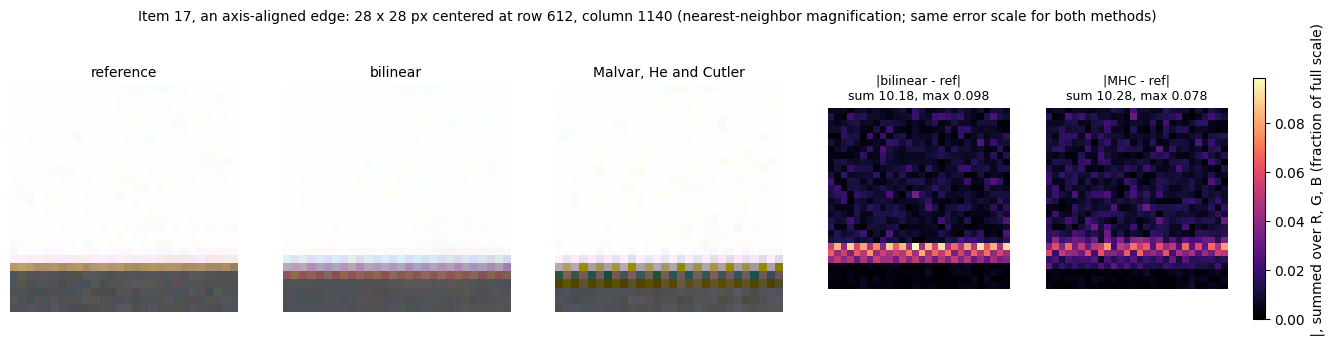

In [18]:
BLOCK = 24                  # analysis block, quarter-resolution pixels
HALF = 14                   # crops are 2*HALF on a side


def block_map(x, f=BLOCK):
    return block_mean(x, f)


err_b = ((bil - ref) ** 2).sum(axis=2)
err_m = ((mhc - ref) ** 2).sum(axis=2)
gy, gx = np.gradient(ref[..., 1])
Eb, Em = block_map(err_b), block_map(err_m)
Gx, Gy = block_map(gx ** 2), block_map(gy ** 2)
strength = Gx + Gy
# Near-vertical or near-horizontal edge: strong gradient, almost all of it along one axis.
axis_aligned = np.maximum(Gx, Gy) / np.maximum(strength, 1e-20) > 0.9
interior = np.zeros_like(Eb, bool); interior[2:-2, 2:-2] = True


def pick(score, mask):
    s = np.where(mask & interior, score, -np.inf)
    by, bx = np.unravel_index(np.argmax(s), s.shape)
    return by * BLOCK + BLOCK // 2, bx * BLOCK + BLOCK // 2


strong = strength > np.percentile(strength[interior], 90)
cy17, cx17 = pick(Eb - Em, axis_aligned & strong)       # edge where MHC helps most
cy18, cx18 = pick(Em - Eb, interior)                     # wherever MHC hurts most


def crop_figure(cy, cx, title, fname):
    sl = (slice(cy - HALF, cy + HALF), slice(cx - HALF, cx + HALF))
    e_b = np.abs(bil[sl] - ref[sl]).sum(axis=2)
    e_m = np.abs(mhc[sl] - ref[sl]).sum(axis=2)
    vmax = max(e_b.max(), e_m.max())
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
    for ax, img, t in zip(axes[:3], (ref, bil, mhc), ("reference", "bilinear", "Malvar, He and Cutler")):
        ax.imshow(disp(img[sl]), interpolation="nearest"); ax.set_title(t, fontsize=10)
    for ax, e, t in zip(axes[3:], (e_b, e_m), ("|bilinear - ref|", "|MHC - ref|")):
        im = ax.imshow(e, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest")
        ax.set_title(f"{t}\nsum {e.sum():.2f}, max {e.max():.3f}", fontsize=9)
    for ax in axes:
        ax.axis("off")
    fig.colorbar(im, ax=axes[3:], shrink=0.8, label="|error|, summed over R, G, B (fraction of full scale)")
    fig.suptitle(f"{title}: {2 * HALF} x {2 * HALF} px centered at row {cy}, column {cx} "
                 f"(nearest-neighbor magnification; same error scale for both methods)", fontsize=10)
    fig.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    return sl


sl17 = crop_figure(cy17, cx17, "Item 17, an axis-aligned edge", "hw5_item17_edge.png")

### Problem 18: Find somewhere the gradient correction doesn't help, or makes things worse, and show it the same way. There's always somewhere.
_Deliverable: One figure of magnified crops with their error maps._

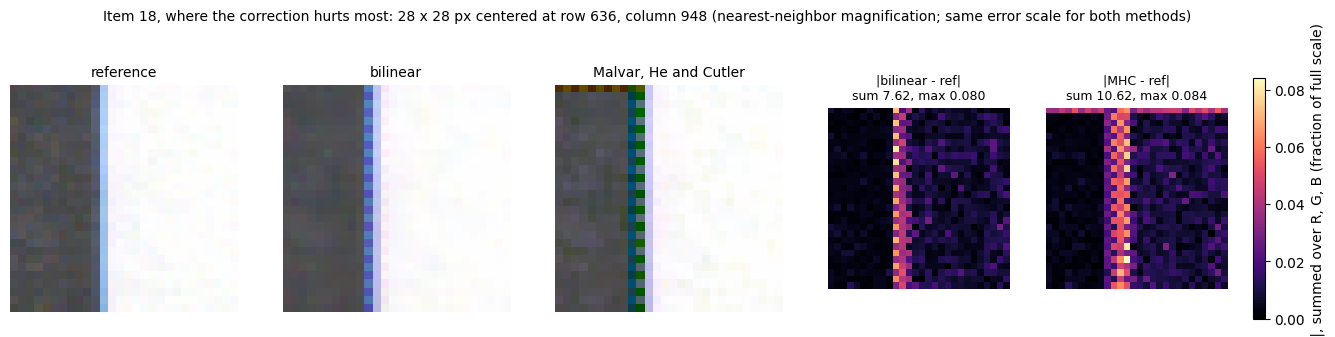

MHC has the larger error in 91% of the 4582 interior 24 x 24 blocks


In [19]:
sl18 = crop_figure(cy18, cx18, "Item 18, where the correction hurts most", "hw5_item18_mhc_worse.png")
share_worse = (Em > Eb)[interior].mean()
print(f"MHC has the larger error in {share_worse:.0%} of the {interior.sum()} interior {BLOCK} x {BLOCK} blocks")

### Problem 19: Name the artifacts you found in the last two figures, and say what kind of image content produced each one.
_Deliverable: Two or three sentences._

On the straight checkerboard edge (item 17), bilinear leaves a **zipper**, a row of alternating light and dark pixels with orange and blue **false color**, because red and blue are interpolated across a sharp black-to-white step. MHC lowers the largest error on the edge (0.078 against 0.098) but replaces the zipper with a fainter green-olive checker. On a vertical checker edge (item 18), MHC is worse (summed error 10.6 against 7.6): a strong **green zipper with overshoot** runs down the edge. The reference itself shows a blue fringe on that edge (and an orange one on the item 17 edge), from the lens's lateral chromatic aberration plus the up-to-one-pixel offset between the R, G and B samples of each 2 &times; 2 block. So red and blue don't follow green there, and adding green's Laplacian to them overshoots. In the flat paper, the same high-&Sigma;w<sup>2</sup> filters turn sensor noise into colored **speckle**, which is why MHC has the larger error in 91% of the 24 &times; 24 blocks: most of the frame is flat.

## Part 4: Reflections
### Problem 20: What did you learn from this assignment?
_Deliverable: A brief written response._

- **A reference for an algorithm has to come from something the algorithm didn't touch**

  The 2 &times; 2 quarter-resolution construction gives three measured values at every pixel, so it can grade a demosaicer, while a demosaiced image would only grade similarity to another demosaicer. The cost is resolution and the single frame's noise.

- **MHC is bilinear plus a zero-sum Laplacian of the channel that was measured at that pixel**

  Writing it that way made the eight cases fall out as four filters, one rotated copy, and the whole method stays a fixed linear operator selected by site masks, with no per-pixel decisions.

- **Border handling is a real part of an implementation, and padding has to respect the CFA**

  Symmetric ("reflect") padding repeats the edge pixel and so swaps colors at the border; mirror padding or averaging only the existing neighbors doesn't. Separating the border from the interior turned "the two implementations disagree" into "they agree to 10<sup>-16</sup> inside and differ only in their padding" (plus, for the lecture MHC, its final clip to [0, 1]).

- **A noisy reference can reverse a ranking**

  MHC's filters have about twice bilinear's sum of squared weights, so they pass more noise, and against a single-frame reference that noise counts as error: MHC scored 0.60 dB below bilinear. Box-averaging the reference, which halves the noise, turned that into 0.62 dB in MHC's favor. That is why Project 2 builds its reference from the averaged burst.

- **Numbers and crops can disagree**

  The PSNR difference is a fraction of a dB, but the crops show zipper and false color on bilinear edges and overshoot and colored noise from MHC, which a single score doesn't separate. They also showed that my "ground truth" has its own color fringe at sharp edges, from chromatic aberration and from the R, G and B samples of a 2 &times; 2 block sitting at different points.

### Problem 21: What questions do you have for me?
_Deliverable: A brief written response._

I have no questions at this time.

### Problem 22: You may use AI tools without limit on this assignment. If you used them, say what you used them for and how you verified the output.
_Deliverable: Two sentences, or a statement that you didn't use them._

I used Claude (Anthropic) to write the demosaicing, reference and evaluation code and to draft the written answers, which I reviewed and edited. I verified it by checking both implementations against the lecture 7 `make_figures.py` versions and against the independent `colour-demosaicing` implementation, with border and interior separated (in the interior they agree to floating-point rounding, once the lecture MHC's final clip to [0, 1] is applied to mine), by asserting that the round trip and both demosaicers return every measured site bit for bit and a constant image exactly, and by confirming that every number in the written answers matches the notebook's printed output.